<a href="https://colab.research.google.com/github/navaneeth20/Aadh/blob/master/Logistic_Regression_Categories.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Logistic Regression Example

Import some libraries to help with your tasks.

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.datasets import load_breast_cancer

In [11]:
# Load breast cancer dataset
cancer = load_breast_cancer()

# Display the dataset description and keys
print("Dataset Keys:", cancer.keys())
print("\nDataset Description Overview:")
print(cancer.DESCR[:1000] + "\n... [Truncated]")

Dataset Keys: dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

Dataset Description Overview:
.. _breast_cancer_dataset:

Breast cancer wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were c

It contains 569 instances with 30 numeric features (like tumor radius, texture, perimeter, and area) calculated from digitized images of fine needle aspirates (FNA) of breast masses.<br>
**Insight:** The output shows that your target classes are malignant (0) and benign (1). This is a binary classification task.

In [13]:
#putting our data in a Dataframe
df = pd.DataFrame(cancer['data'],columns = cancer['feature_names'])

In [14]:
df.head()     #Shows top 5 data entry

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [15]:
df.describe()   # Decribe about the data

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


**What it does:** Structures the raw NumPy array into a clean Pandas DataFrame, displays a summary, and plots a correlation matrix heatmap.<br>
**Insight:**<br>
**No Missing Values:** df.isnull().sum() outputs 0 across all columns, meaning no imputation is necessary.<br>
**Multicollinearity:** The heatmap reveals very bright clusters (correlation close to 1.0) among features like mean radius, mean perimeter, and mean area. Since they all scale with tumor size, this is expected. While Logistic Regression can handle collinear features for prediction, it can make individual coefficient values unstable or harder to interpret structurally.

<Axes: >

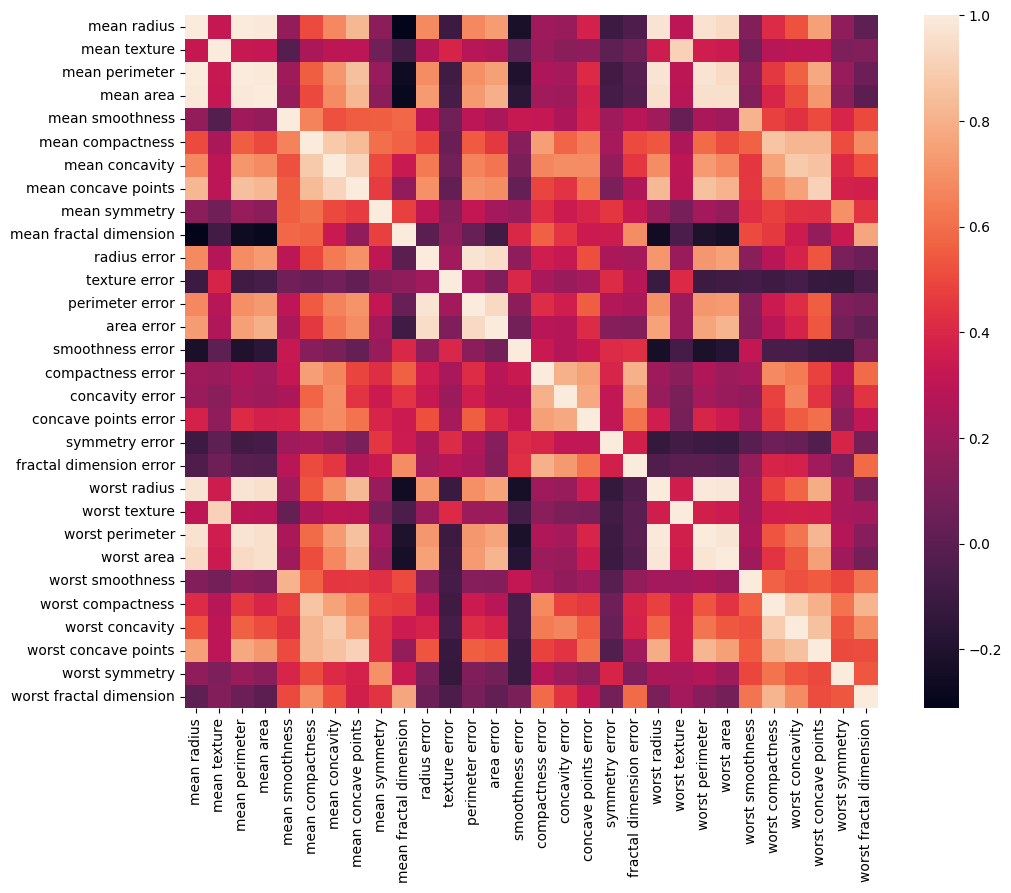

In [16]:
import seaborn as sn
corrmat = df.corr()
feature, axis = plt.subplots(figsize = (12,9))
sn.heatmap(corrmat,square=True)

In [17]:
df.isnull().sum()

,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


In [18]:
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = cancer.target

print("Classes:", cancer.target_names)
print("Shape of features:", X.shape)
X.head()

Classes: ['malignant' 'benign']
Shape of features: (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


**Train-Test Split**

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

**What it does:** Splits the dataset into 80% training and 20% testing sets. `stratify=y` ensures that both subsets maintain the same ratio of malignant vs. benign samples. `max_iter=5000` gives the solver plenty of iterations to find the global minimum without throwing convergence warnings.<br>
**Insight:** The model successfully converged with an intercept of `29.02` and `30` coefficients (one weight assigned to each feature).

**Train Model**

In [23]:
log_reg = LogisticRegression(max_iter=5000)  # increase iterations for convergence
log_reg.fit(X_train, y_train)

print("Intercept:", log_reg.intercept_)
print("Number of coefficients:", len(log_reg.coef_[0]))

Intercept: [29.02246525]
Number of coefficients: 30


**Predictions & Evaluation**

Accuracy: 0.9649122807017544

Classification Report:
              precision    recall  f1-score   support

   malignant       0.97      0.93      0.95        42
      benign       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



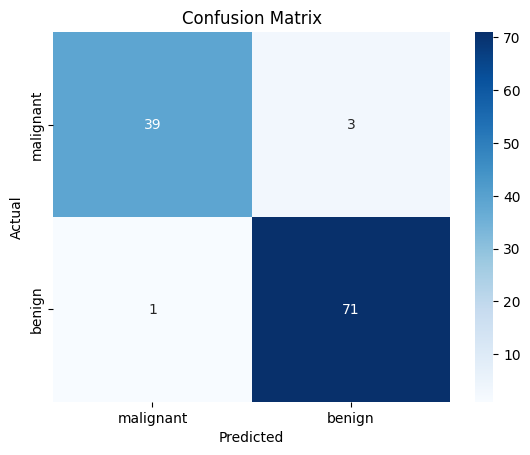

In [26]:
y_pred = log_reg.predict(X_test)
y_prob = log_reg.predict_proba(X_test)[:,1]  # probability of class 1

# Evaluation metrics
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=cancer.target_names))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=cancer.target_names, yticklabels=cancer.target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

This is where we get our performance metrics:<br>

**Accuracy (0.965):** Your model correctly classifies 96.5% of the test cases.<br>
**Confusion Matrix:**<br>
**39 True Negatives (Malignant):** Malignant cases correctly classified.<br>
**71 True Positives (Benign):** Benign cases correctly classified.<br>
**3 False Positives:** Malignant cases incorrectly flagged as benign.<br>
**1 False Negative:** Benign case incorrectly flagged as malignant.<br>


**ROC Curve (Optional, for better evaluation)**


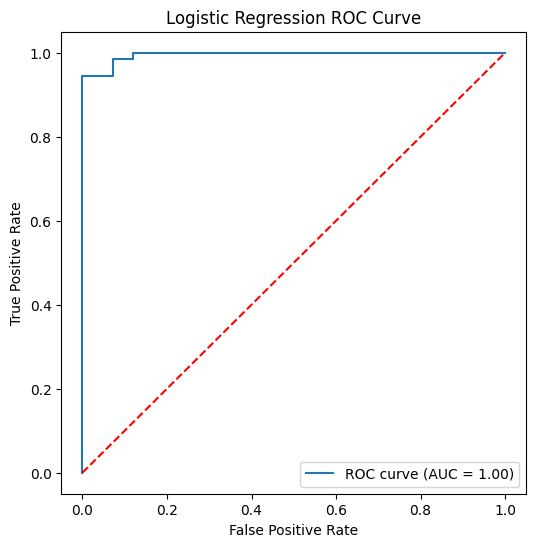

In [27]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label="ROC curve (AUC = %.2f)" % roc_auc)
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression ROC Curve")
plt.legend(loc="lower right")
plt.show()

**ROC Curve & AUC (1.00):**<br>
The Area Under the ROC Curve (AUC) is rounded to `1.00` (specifically `0.995` based on your variables). This shows that your model has exceptional discriminative power to distinguish between malignant and benign tissues across almost all probability thresholds.

**Real-Life Applications of Logistic Regression**

🏥 Healthcare: Predicting whether a patient has a disease (Yes/No).<br>
📧 Spam Detection: Classifying emails as spam/not spam.<br>
💳 Finance: Predicting loan default (will repay vs will not).<br>
🎬 Marketing: Predicting whether a user will click on an ad (CTR prediction).<br>
🏢 HR: Employee attrition prediction (Will leave job: Yes/No).<br>

**Key Takeaways**<br>
Linear Regression → predicts continuous outcomes.<br>
Logistic Regression → predicts probabilities for categories.<br>
Both rely on gradient descent optimization.<br>
Simple, interpretable, and widely used in industry.<br>